In [7]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
llm = ChatGroq(model="qwen/qwen3.8-27b", max_tokens=500)

In [18]:
# define state 
class BlogState(TypedDict):

    title: str
    outline: str
    content: str
    rating: int

In [11]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title 
    title = state['title']

    # call llm gen ouline 
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = llm.invoke(prompt).content

    # update state 
    state['outline'] = outline

    return state

In [12]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the following outline -\n {outline}'

    blog = llm.invoke(prompt).content

    state['content'] = blog

    return state

In [26]:
def evaluate_rating(state: BlogState) -> BlogState:

    blog = state['content']

    prompt = f'Evaluate the following blog and generate score between 1 to 10. Output should be number. The blog is as follows - \n {blog}'
    score = llm.invoke(prompt).content

    state['rating'] = score

    return state

In [27]:
# define graph 
graph = StateGraph(BlogState)

# add nodes 
graph.add_node("create_outline", create_outline)
graph.add_node("create_blog", create_blog)
graph.add_node("evaluate_rating", evaluate_rating)

# add edges 
graph.add_edge(START, "create_outline")
graph.add_edge("create_outline", "create_blog")
graph.add_edge("create_blog", "evaluate_rating")
graph.add_edge("evaluate_rating", END)

workflow = graph.compile()

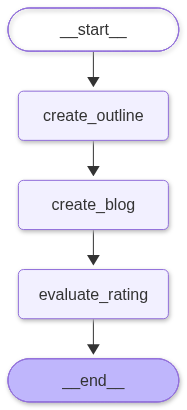

In [28]:
workflow

In [29]:
initial_state = {'title':'Which business will not be impacted by AI?'}

final_state = workflow.invoke(initial_state)

print(final_state)

{'title': 'Which business will not be impacted by AI?', 'outline': 'Here is a detailed outline for a blog post exploring the nuance of the question "Which business will not be impacted by AI?"\n\n**Core Thesis:** The premise of the question is a trap. No business will be *unaffected* by AI. However, some businesses will be **less susceptible to direct job displacement** or **structural disruption** compared to others. The focus should shift from "who is immune?" to "who is resilient?" and "who must adapt differently?"\n\n---\n\n# Blog Title Ideas\n*   **The AI Immunity Myth: Why No Business Is Truly Safe (But Some Are Sturdier)**\n*   **Beyond the Hype: Identifying Businesses with High AI Resilience**\n*   **Which Businesses Will Survive AI? A Realistic Assessment of Risk and Resilience**\n\n---\n\n## I. Introduction\n*   **Hook:** Start with the widespread anxiety about AI replacing jobs, from baristas to bankers.\n*   **The Misconception:** Address the common question: "Is there *any

In [23]:
print(final_state['outline'])

Here is a detailed outline for a blog post exploring the topic of businesses resilient to Artificial Intelligence. The structure is designed to be engaging, nuanced, and authoritative, moving from the common perception of "AI replaces everything" to a more realistic view of "AI transforms, but some sectors remain human-centric."

---

# Blog Title Options
*   **Option 1 (Provocative):** The AI-Proof Business: Why Some Industries Will Never Be Automated
*   **Option 2 (Analytical):** Beyond the Hype: Identifying Business Models Resistant to AI Disruption
*   **Option 3 (Practical):** How to Build a Business That AI Can’t Replace: A Strategic Guide

## I. Introduction
*   **The Hook:** Start with a compelling statistic or anecdote about the rapid adoption of AI in creative and technical fields (e.g., code generation, copywriting, design).
*   **The Common Fear:** Acknowledge the widespread anxiety that "AI will take our jobs" or "AI will disrupt every industry."
*   **The Thesis Statemen

In [24]:
print(final_state['content'])

# Beyond the Hype: Identifying Business Models Resistant to AI Disruption

The air in modern boardrooms and coffee shops is thick with a new kind of anxiety. It’s the same panic that gripped the world during the Industrial Revolution, but this time, the machine that is taking over isn’t just weaving cloth; it’s writing code, generating marketing copy, diagnosing diseases, and designing logos. We live in an era where an AI can produce a symphony in seconds or draft a legal brief in minutes. The narrative is seductive in its simplicity: *AI will replace everything.*

But is that true?

While it is undeniable that Artificial Intelligence will transform almost every sector we know, it is a dangerous oversimplification to claim it will erase them. There is a distinct difference between *automating a task* and *replacing a business*. If you look closely at the structure of certain industries, you will find businesses that are structurally, psychologically, and ethically resistant to full aut

In [30]:
print(final_state['rating'])

9
